In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

df = pd.read_csv("/content/dataset_part_2.csv")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (90, 18)
Columns: ['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude', 'Class']


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


In [2]:
# Clean column names
df.columns = df.columns.str.strip()

# Check target column
if "Class" not in df.columns:
    raise ValueError("Class column not found. Check the printed column names.")

# Select available useful features
candidate_features = [
    "FlightNumber", "PayloadMass", "Orbit", "LaunchSite",
    "Flights", "GridFins", "Reused", "Legs", "Block", "ReusedCount"
]

features = [col for col in candidate_features if col in df.columns]

X = df[features].copy()
y = pd.to_numeric(df["Class"], errors="coerce")

# Remove rows with missing target
valid_rows = y.notna()
X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].astype(int)

# Convert categorical features into numeric columns
X = pd.get_dummies(X, columns=X.select_dtypes(include=["object", "category"]).columns,
                   dummy_na=True, dtype=int)

# Convert all features to numeric and handle missing values
X = X.apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median()).fillna(0)

print("Features used:", features)
print("Prepared feature shape:", X.shape)
print("Target distribution:")
print(y.value_counts().sort_index())

Features used: ['FlightNumber', 'PayloadMass', 'Orbit', 'LaunchSite', 'Flights', 'GridFins', 'Reused', 'Legs', 'Block', 'ReusedCount']
Prepared feature shape: (90, 24)
Target distribution:
Class
0    30
1    60
Name: count, dtype: int64


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 67
Testing rows: 23


In [4]:
models = {
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(max_depth=4, random_state=42))
    ]),

    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=42))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="linear"))
    ])
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy * 100, 2)
    })

    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values(
    by="Accuracy (%)", ascending=False
)

display(results_df)

,Model,Accuracy (%)
0,Decision Tree,82.61
3,SVM,82.61
1,KNN,78.26
2,Logistic Regression,78.26


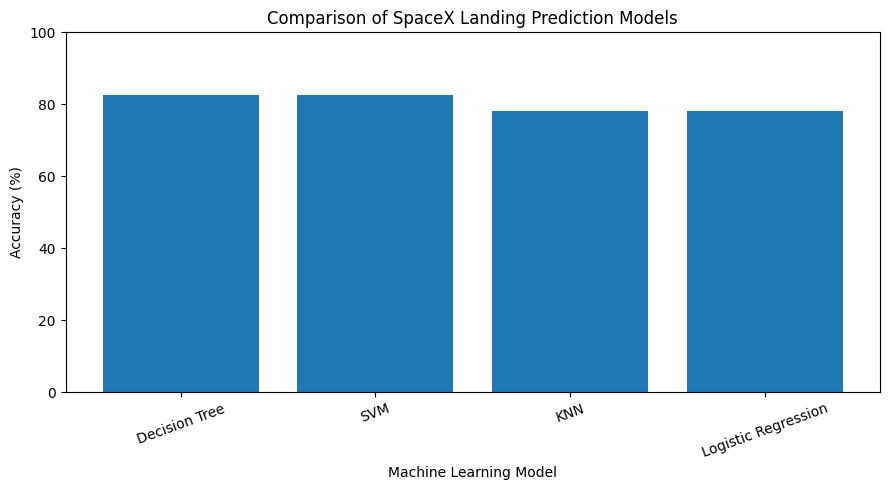

In [5]:
plt.figure(figsize=(9, 5))

plt.bar(results_df["Model"], results_df["Accuracy (%)"])
plt.ylabel("Accuracy (%)")
plt.xlabel("Machine Learning Model")
plt.title("Comparison of SpaceX Landing Prediction Models")
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

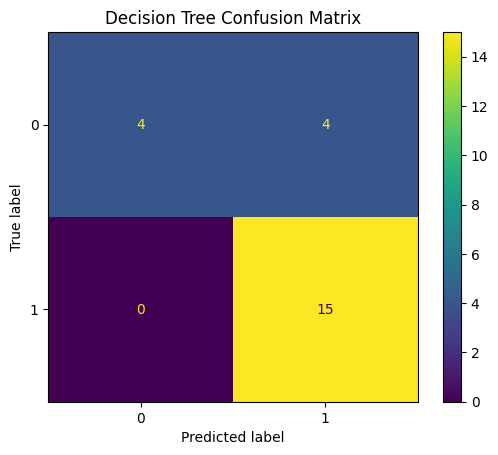

              precision    recall  f1-score   support

           0       1.00      0.50      0.67         8
           1       0.79      1.00      0.88        15

    accuracy                           0.83        23
   macro avg       0.89      0.75      0.77        23
weighted avg       0.86      0.83      0.81        23



In [6]:
best_model = trained_models["Decision Tree"]
y_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_model.classes_
)

display.plot()
plt.title("Decision Tree Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred, zero_division=0))

Conclusion
Four machine-learning models—Decision Tree, K-Nearest Neighbors, Logistic Regression, and Support Vector Machine—were trained to predict the target class using selected SpaceX launch features. Their performance was compared using test-set accuracy, and a confusion matrix was used to evaluate the Decision Tree model. The best-performing model is identified from the measured results. Because the dataset and test set are relatively small, the results should be interpreted cautiously and may not generalize to future launches.